# Backtracking line search demo

This notebook walks through the Armijo backtracking line search implemented in
`trigger_agent_misc.optimization.line_search`. Run from the repo root after
`uv sync` so the editable package is on the path.

In [1]:
%matplotlib inline

import matplotlib.pyplot as plt

from trigger_agent_misc.optimization.line_search import backtracking_armijo

## Quadratic model along a descent direction

Along a ray with ``phi(alpha) = (1 - alpha)^2``, the minimizer is ``alpha = 1``.

In [2]:
def phi(alpha: float) -> float:
    return (1.0 - alpha) ** 2

result = backtracking_armijo(phi, phi_prime_at_zero=-2.0, alpha0=1.0)
result

LineSearchResult(alpha=1.0, value=0.0, iterations=0)

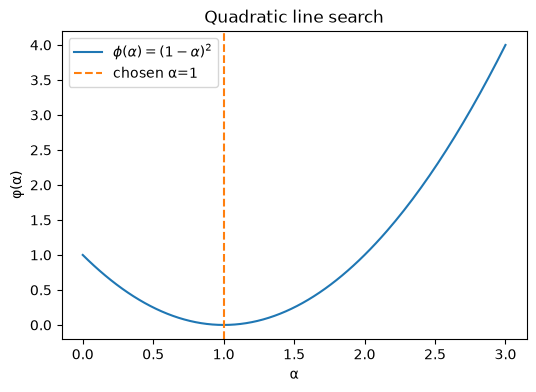

In [3]:
alphas = [i / 50 for i in range(0, 151)]
values = [phi(a) for a in alphas]

plt.figure(figsize=(6, 4))
plt.plot(alphas, values, label=r"$\phi(\alpha) = (1-\alpha)^2$")
plt.axvline(result.alpha, color="C1", linestyle="--", label=f"chosen α={result.alpha:.3g}")
plt.xlabel("α")
plt.ylabel("φ(α)")
plt.title("Quadratic line search")
plt.legend()
plt.show()

## Rosenbrock: one steepest-descent step from the origin

We restrict the 2D Rosenbrock function to the ray ``x + alpha p`` where
``p`` is the negative gradient at ``(0, 0)``.

In [4]:
def rosenbrock(x: float, y: float) -> float:
    return (1.0 - x) ** 2 + 100.0 * (y - x**2) ** 2

x0, y0 = 0.0, 0.0
grad = (-2.0, 0.0)
direction = (-grad[0], -grad[1])
phi_prime0 = grad[0] * direction[0] + grad[1] * direction[1]

def phi_r(alpha: float) -> float:
    return rosenbrock(x0 + alpha * direction[0], y0 + alpha * direction[1])

rosen_result = backtracking_armijo(phi_r, phi_prime_at_zero=phi_prime0, alpha0=1.0)
{
    "alpha": rosen_result.alpha,
    "f_before": rosenbrock(x0, y0),
    "f_after": rosen_result.value,
    "iterations": rosen_result.iterations,
}

{'alpha': 0.125, 'f_before': 1.0, 'f_after': 0.953125, 'iterations': 3}

See also ``evals/line_search_eval.py`` for scripted metrics used in experiments.